In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('Final_project.csv')

In [ ]:
df.head()

In [4]:
df['Family'].isna().sum()

np.int64(3)

In [5]:
df["Family"]=df["Family"].fillna(df["Family"].mean())

In [6]:
df

,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health,Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176
...,...,...,...,...,...,...,...,...,...,...,...,...
153,Rwanda,Sub-Saharan Africa,154,3.465,0.03464,0.22208,0.77370,0.42864,0.59201,0.55191,0.22628,0.67042
154,Benin,Sub-Saharan Africa,155,3.340,0.03656,0.28665,0.35386,0.31910,0.48450,0.08010,0.18260,1.63328
155,Syria,Middle East and Northern Africa,156,3.006,0.05015,0.66320,0.47489,0.72193,0.15684,0.18906,0.47179,0.32858
156,Burundi,Sub-Saharan Africa,157,2.905,0.08658,0.01530,0.41587,0.22396,0.11850,0.10062,0.19727,1.83302


In [22]:
df.isna().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Standard Error                   0
Economy (GDP per Capita)         0
Family                           0
Health                           0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

In [23]:
sum_sta=df[['Happiness Rank','Standard Error','Freedom']].describe()
sum_sta

,Happiness Rank,Standard Error,Freedom
count,158.000000,158.000000,158.000000
mean,79.493671,0.047885,0.428615
std,45.754363,0.017146,0.150693
min,1.000000,0.018480,0.000000
25%,40.250000,0.037268,0.328330
50%,79.500000,0.043940,0.435515
75%,118.750000,0.052300,0.549092
max,158.000000,0.136930,0.669730


In [24]:
correlation_matrix=df[['Happiness Rank','Standard Error','Freedom']].corr()
correlation_matrix

,Happiness Rank,Standard Error,Freedom
Happiness Rank,1.000000,0.158516,-0.556886
Standard Error,0.158516,1.000000,-0.129773
Freedom,-0.556886,-0.129773,1.000000


In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

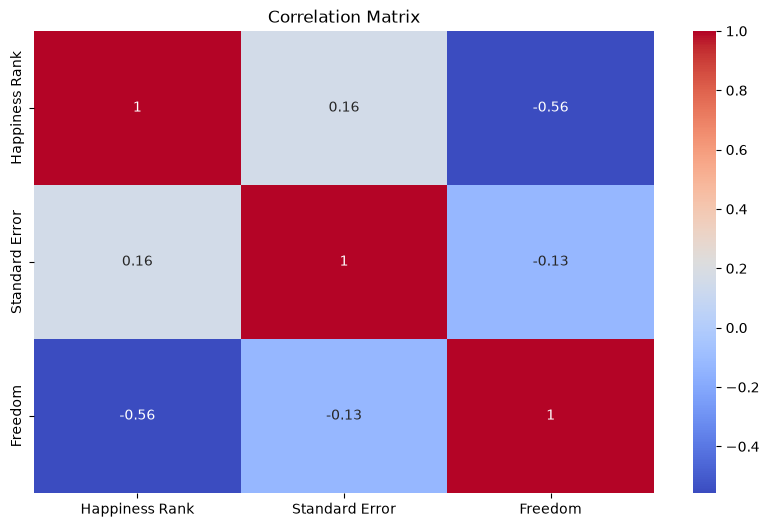

In [26]:
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [28]:
top_score=df.groupby('Country')['Happiness Score'].sum().nlargest(5)
top_score

Country
Switzerland    7.587
Iceland        7.561
Denmark        7.527
Norway         7.522
Canada         7.427
Name: Happiness Score, dtype: float64

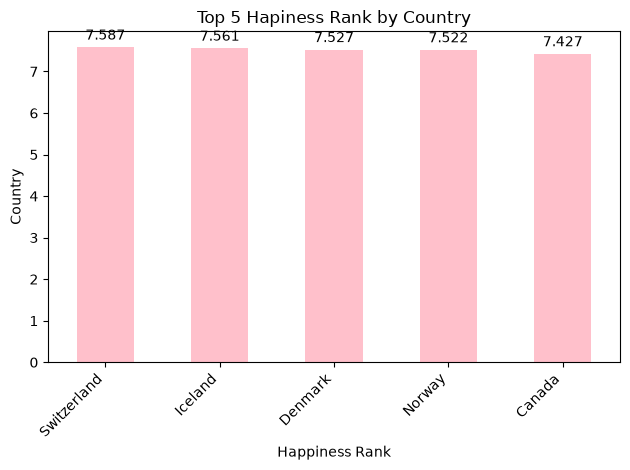

In [29]:
ax=top_score.plot(kind='bar',color='pink')
plt.bar_label(ax.containers[0], fmt='%.3f', padding=3)

plt.title('Top 5 Hapiness Rank by Country')
plt.xlabel('Happiness Rank')
plt.ylabel('Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [30]:
region_hapiness=df.groupby('Region')['Happiness Score'].mean()
region_hapiness

Region
Australia and New Zealand          7.285000
Central and Eastern Europe         5.332931
Eastern Asia                       5.626167
Latin America and Caribbean        6.144682
Middle East and Northern Africa    5.406900
North America                      7.273000
Southeastern Asia                  5.317444
Southern Asia                      4.580857
Sub-Saharan Africa                 4.202800
Western Europe                     6.689619
Name: Happiness Score, dtype: float64

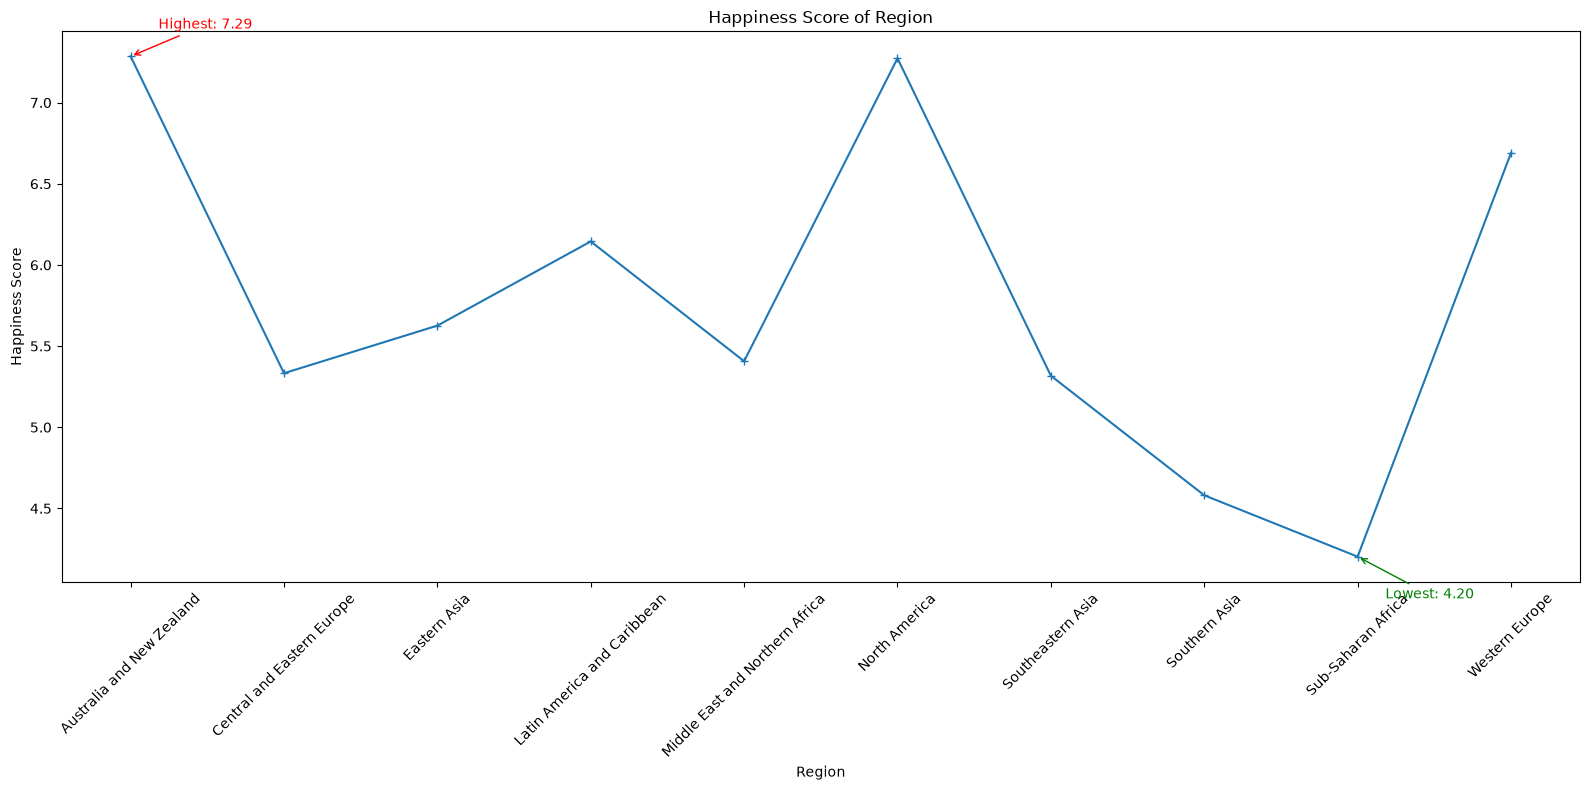

In [31]:
plt.figure(figsize=(16,8))

plt.plot(range(len(region_hapiness)), region_hapiness.values, marker='+')

plt.xticks(range(len(region_hapiness)), region_hapiness.index, rotation=45)

plt.title('Happiness Score of Region')
plt.xlabel('Region')
plt.ylabel('Happiness Score')

max_region = region_hapiness.idxmax()
min_region = region_hapiness.idxmin()

max_pos = region_hapiness.index.get_loc(max_region)
min_pos = region_hapiness.index.get_loc(min_region)

plt.annotate(
    f'Highest: {region_hapiness[max_region]:.2f}',
    xy=(max_pos, region_hapiness[max_region]),
    xytext=(20, 20),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='red'),
    color='red'
)

plt.annotate(
    f'Lowest: {region_hapiness[min_region]:.2f}',
    xy=(min_pos, region_hapiness[min_region]),
    xytext=(20, -30),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='green'),
    color='green'
)

plt.tight_layout()
plt.show()

In [32]:
region_economy = df.groupby('Region')['Economy (GDP per Capita)'].mean()

region_economy

Region
Australia and New Zealand          1.291880
Central and Eastern Europe         0.942438
Eastern Asia                       1.151780
Latin America and Caribbean        0.876815
Middle East and Northern Africa    1.066974
North America                      1.360400
Southeastern Asia                  0.789054
Southern Asia                      0.560486
Sub-Saharan Africa                 0.380473
Western Europe                     1.298596
Name: Economy (GDP per Capita), dtype: float64

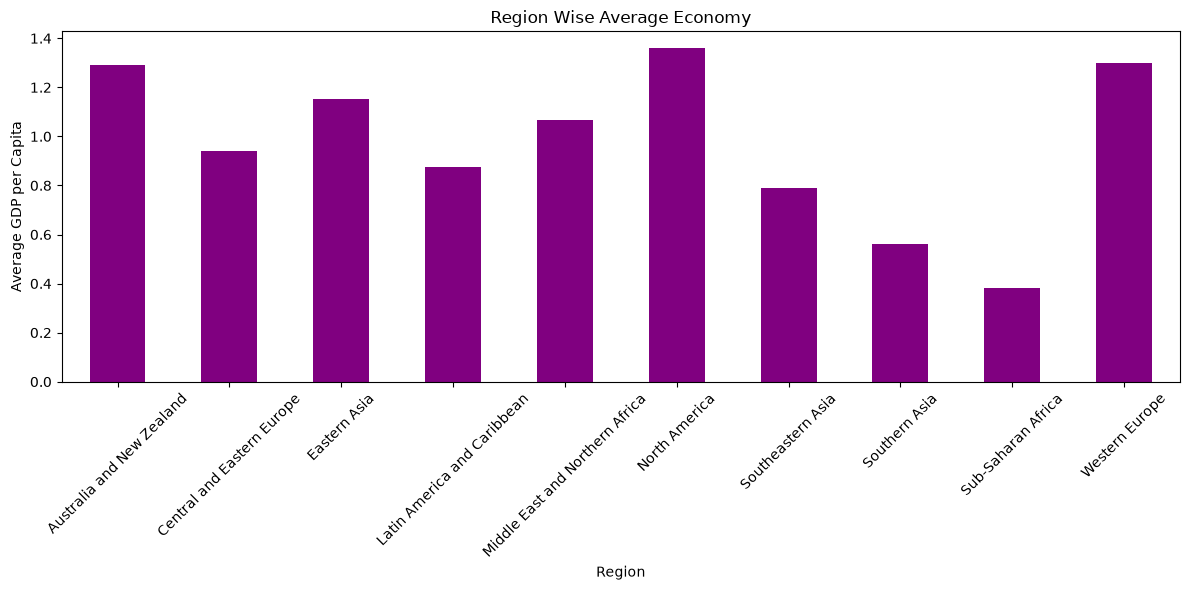

The region with the highest Economy is North America with a Average GDP per Capita of1.3603999999999998


In [34]:
plt.figure(figsize=(12,6))

region_economy.plot(kind='bar', color='purple')

plt.title('Region Wise Average Economy')
plt.xlabel('Region')
plt.ylabel('Average GDP per Capita')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

growth_region=region_economy.idxmax()
growth_value=region_economy.max()
print(f'The region with the highest Economy is {growth_region} with a Average GDP per Capita of{growth_value}')

In [38]:
# Region-wise Happiness Classification

region_data = df.groupby('Region').agg({
    'Country': 'count',
    'Happiness Score': 'mean',
    'Economy (GDP per Capita)': 'mean',
    'Family': 'mean',
    'Health ': 'mean',
    'Freedom': 'mean',
    'Generosity': 'mean'
}).rename(columns={
    'Country': 'CountryCount',
    'Happiness Score': 'AvgHappinessScore',
    'Economy (GDP per Capita)': 'AvgEconomy',
    'Family': 'AvgFamily',
    'Health ': 'AvgHealth',
    'Freedom': 'AvgFreedom',
    'Generosity': 'AvgGenerosity'
})

region_data

,CountryCount,AvgHappinessScore,AvgEconomy,AvgFamily,AvgHealth,AvgFreedom,AvgGenerosity
Region,,,,,,,
Australia and New Zealand,2,7.285000,1.291880,1.314450,0.919965,0.645310,0.455315
Central and Eastern Europe,29,5.332931,0.942438,1.053042,0.718774,0.358269,0.152264
Eastern Asia,6,5.626167,1.151780,1.099427,0.877388,0.462490,0.225885
Latin America and Caribbean,22,6.144682,0.876815,1.096700,0.703870,0.501740,0.217788
Middle East and Northern Africa,20,5.406900,1.066974,0.920490,0.705615,0.361751,0.190376
North America,2,7.273000,1.360400,1.284860,0.883710,0.589505,0.429580
Southeastern Asia,9,5.317444,0.789054,0.940468,0.677357,0.557104,0.419261
Southern Asia,7,4.580857,0.560486,0.645321,0.540830,0.373337,0.341429
Sub-Saharan Africa,40,4.202800,0.380473,0.809085,0.282332,0.365944,0.221137


Australia and New Zealand Countries: 2
Central and Eastern Europe Countries: 29
Eastern Asia Countries: 6
Latin America and Caribbean Countries: 22
Middle East and Northern Africa Countries: 20
North America Countries: 2
Southeastern Asia Countries: 9
Southern Asia Countries: 7
Sub-Saharan Africa Countries: 40
Western Europe Countries: 21


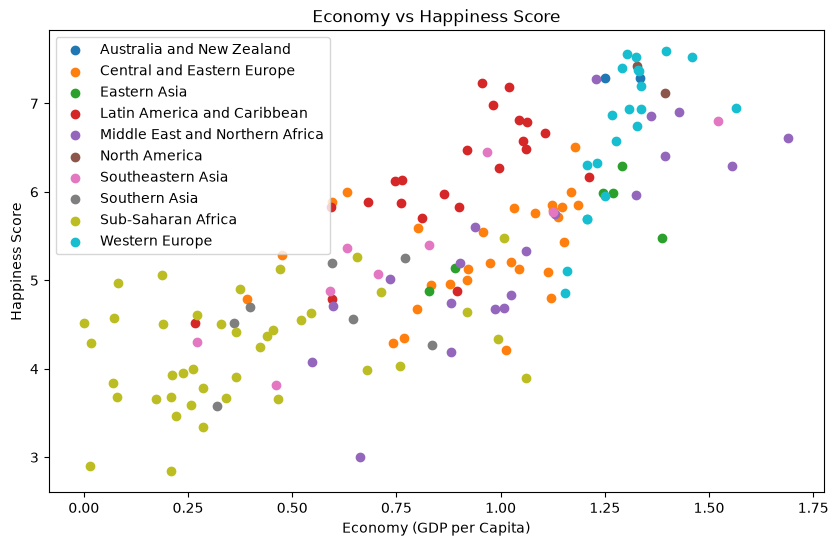

In [35]:
# Scatter Plot

plt.figure(figsize=(10, 6))

for label, group in df.groupby('Region'):
    print(f'{label} Countries: {len(group)}')
    plt.scatter(group['Economy (GDP per Capita)'], group['Happiness Score'], label=label)

plt.xlabel('Economy (GDP per Capita)')
plt.ylabel('Happiness Score')
plt.title('Economy vs Happiness Score')
plt.legend()
plt.show()